# Forecasting Brazil's 2026 presidential runoff: a pre-registered, reproducible model

**Part A of 3: the forecast, frozen before the polls close (2026-10-25, 17:00 GMT-3).** Part B (`02_polarization.ipynb`) covers the social science of a 50/50 country. Part C (`03_scoring.ipynb`) scores this forecast against the official result.

**Not an endorsement.** This is a measurement exercise. The author doesn't vote, has no side, and makes no claim about who *should* win. A probability here is a calibrated statement about uncertainty, not a wish.

Design, constants and scoring rules were fixed in `EXPERIMENT.md` before any model ran. Every deviation is logged there with a timestamp and a reason. Every number in this notebook comes from `results/ledger.csv`, which is append-only and written by `src/forecast.py`.

In [1]:
import sys, platform, json, datetime as dt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, scipy, pymc, arviz as az
import forecast as F
matplotlib.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
env = {"python": platform.python_version(), "platform": platform.platform(), "numpy": np.__version__,
       "pandas": pd.__version__, "scipy": scipy.__version__, "pymc": pymc.__version__, "arviz": az.__version__,
       "harness_commit": F.harness_commit(), "data_manifest_sha256": F.manifest_hash(),
       "executed_at_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}
F.verify_manifest()   # raises if any raw file differs from the pre-registered snapshot
env

{'python': '3.12.15',
 'platform': 'Linux-7.2.7+rex-amd64-x86_64-with-glibc2.41',
 'numpy': '2.2.6',
 'pandas': '2.2.3',
 'scipy': '1.15.3',
 'pymc': '5.23.0',
 'arviz': '0.21.0',
 'harness_commit': 'dd9c3fb003f0922ab3bbf72213bd324f2bb2d389',
 'data_manifest_sha256': '8a67fe7befece13216e0b59347f8f7626f827c57e963b8a61f5ba7783ba72420',
 'executed_at_utc': '2026-10-25T03:14:39+00:00'}

## 1. Data

There are 59 national runoff polls published from 2026-10-08 to 2026-10-24. One release is excluded because its TSE registration couldn't be confirmed, which leaves 58. Every row carries its source URL and TSE registration number.

The rows were compiled from public reports by two independent compilations and cross-checked. Where they disagreed, the row says so in `flag`. The measure is Flávio Bolsonaro's **two-party valid-vote share**, Flávio / (Flávio + Lula), in percentage points. Each poll is dated at its field midpoint.

In [2]:
polls = F.load_polls()
print(f"{len(polls)} polls, {polls.pollster.nunique()} pollsters, field midpoints {polls.mid.min():%m-%d} to {polls.mid.max():%m-%d}")
polls[["pollster","published","field_start","field_end","n","mode","tse_reg","y","se","flag"]].round(2)

58 polls, 22 pollsters, field midpoints 10-05 to 10-23


,pollster,published,field_start,field_end,n,mode,tse_reg,y,se,flag
0,AtlasIntel,2026-10-09,2026-10-03,2026-10-08,5026,O,BR-03663/2026,52.80,1.05,field began before the 1st round (Oct 4)
1,PoderData,2026-10-08,2026-10-05,2026-10-07,3000,URA,BR-08134/2026,53.00,1.36,NaN
2,Vox Brasil,2026-10-09,2026-10-05,2026-10-07,2100,P,BR-09623/2026,49.10,1.63,NaN
3,Datafolha,2026-10-08,2026-10-06,2026-10-07,2520,P,BR-02949/2026,52.00,1.48,NaN
4,Ipespe/Abrapel,2026-10-10,2026-10-06,2026-10-08,1500,T,BR-00933/2026,52.70,1.92,NaN
5,DataTrends,2026-10-11,2026-10-07,2026-10-09,2000,URA,BR-03576/2026,53.10,1.66,NaN
6,Futura,2026-10-13,2026-10-07,2026-10-10,2000,T,BR-00650/2026,51.80,1.67,NaN
7,Gerp,2026-10-13,2026-10-08,2026-10-12,2400,T,BR-07877/2026,55.00,1.51,NaN
8,BTG/Nexus,2026-10-13,2026-10-10,2026-10-12,2002,T,BR-07997/2026,51.60,1.66,NaN
9,PoderData,2026-10-13,2026-10-10,2026-10-12,3000,URA,BR-01209/2026,51.00,1.36,NaN


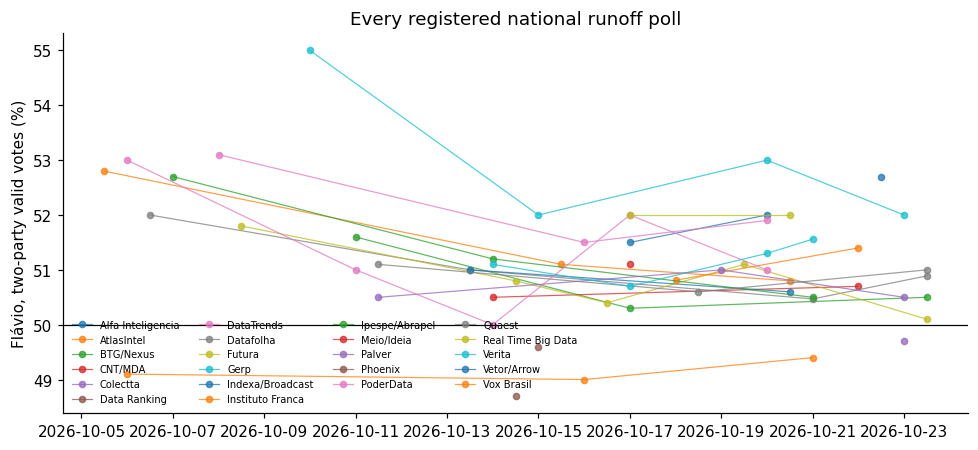

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for h, g in polls.groupby("pollster"):
    ax.plot(g["mid"], g["y"], "o-", ms=4, lw=0.8, alpha=0.75, label=h)
ax.axhline(50, color="k", lw=0.8)
ax.set_ylabel("Flávio, two-party valid votes (%)"); ax.set_title("Every registered national runoff poll")
ax.legend(ncol=4, fontsize=6.5, frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "polls.png"); plt.show()

## 2. How wrong have the polls been?

This is the single most important input, so it gets its own section. The model needs to know how far an eve-of-election poll lands from the result. Three bodies of evidence follow:

1. **Datafolha, the eve of every runoff from 2002 to 2022.** It is the only pollster with a long, consistent series. This is the calibration set the forecast uses.
2. **All the major pollsters on the eve of the 2022 runoff.** This shows how much pollsters disagree within one year.
3. **The final polls of the 2026 first round.** A first round isn't a runoff, because tactical late switching to a viable candidate inflates first-round misses. It is the most recent evidence, though, and it pointed one way.

In [4]:
h = pd.read_csv(F.RAW / "hist_datafolha_runoffs.csv")
h["error_nonpt_pp"] = h["result_pt_vv"] - h["poll_pt_vv"]      # poll minus result, non-PT finalist
e = h["error_nonpt_pp"]
print(f"Datafolha eve-of-runoff error on the non-PT finalist, 2002-2022: mean {e.mean():+.2f} pp, "
      f"SD {e.std(ddof=1):.2f} pp, RMSE {np.sqrt((e**2).mean()):.2f} pp, n={len(e)}")
h[["year","pt_candidate","nonpt_candidate","poll_pt_vv","result_pt_vv","error_nonpt_pp"]]

Datafolha eve-of-runoff error on the non-PT finalist, 2002-2022: mean -0.57 pp, SD 1.26 pp, RMSE 1.29 pp, n=6


,year,pt_candidate,nonpt_candidate,poll_pt_vv,result_pt_vv,error_nonpt_pp
0,2002,Lula,Serra,64.0,61.27,-2.73
1,2006,Lula,Alckmin,61.0,60.83,-0.17
2,2010,Dilma,Serra,55.0,56.05,1.05
3,2014,Dilma,Aecio,52.0,51.64,-0.36
4,2018,Haddad,Jair Bolsonaro,45.0,44.87,-0.13
5,2022,Lula,Jair Bolsonaro,52.0,50.90,-1.10


In [5]:
h22 = pd.read_csv(F.RAW / "hist_2022_eve_pollsters.csv")
h22["error_pt_pp"] = h22["poll_pt_vv"] - h22["result_pt_vv"]
r1 = pd.DataFrame({"pollster": pd.read_csv(F.RAW / "r1_2026_final_polls.csv")["pollster"],
                   "error_flavio_two_party_pp": F.r1_2026_two_party_errors().round(2)})
print(f"2022 eve, 6 pollsters: mean error on Lula {h22.error_pt_pp.mean():+.2f} pp (every one overstated PT)")
print(f"2026 first round, 11 pollsters: mean two-party error on Flávio {r1.iloc[:,1].mean():+.2f} pp, "
      f"{(r1.iloc[:,1] < 0).sum()} of {len(r1)} understated him")
display(h22); display(r1)

2022 eve, 6 pollsters: mean error on Lula +1.25 pp (every one overstated PT)
2026 first round, 11 pollsters: mean two-party error on Flávio -1.79 pp, 8 of 11 understated him


,pollster,published,poll_pt_vv,result_pt_vv,source_url,error_pt_pp
0,CNT/MDA,2022-10-29,51.1,50.9,https://www.bol.uol.com.br/noticias/2022/10/29...,0.2
1,Parana Pesquisas,2022-10-29,50.4,50.9,https://www.bol.uol.com.br/noticias/2022/10/29...,-0.5
2,Datafolha,2022-10-29,52.0,50.9,https://www.bol.uol.com.br/noticias/2022/10/29...,1.1
3,Quaest,2022-10-29,52.0,50.9,https://www.bol.uol.com.br/noticias/2022/10/29...,1.1
4,AtlasIntel,2022-10-29,53.4,50.9,https://www.bol.uol.com.br/noticias/2022/10/29...,2.5
5,Ipec,2022-10-29,54.0,50.9,https://www.bol.uol.com.br/noticias/2022/10/29...,3.1


,pollster,error_flavio_two_party_pp
0,Datafolha,-2.74
1,Quaest,-1.56
2,AtlasIntel,-2.60
3,PoderData,-2.15
4,Real Time Big Data,-3.45
5,Futura,0.25
6,CNT/MDA,-4.18
7,Gerp,0.12
8,Vox Brasil,-0.52
9,Palver,1.21


**The reading.** Since 2014, the misses have mostly run the same way, with polls understating the non-PT finalist. The size varies a lot. The model doesn't hard-code a correction. It treats the industry's bias as uncertain, with a mean learned from the six-runoff Datafolha series and a spread that reflects how little six data points can tell us. Arm M4 asks what happens if 2026's first-round miss is taken as a seventh observation.

## 3. Are the final polls herding?

Pollsters who fear being the outlier can drift toward the consensus. If the last polls agree with each other *more* than their sample sizes allow, that is a warning sign. The test below compares the observed dispersion with pure binomial sampling error (design effect 1). It uses each pollster's last poll with field ending on or after 2026-10-20.

In [6]:
herd = F.herding_test(); herd

{'k': 19,
 'weighted_mean': 51.08244072761744,
 'chi2': 14.25426148201945,
 'dof': 18,
 'ratio': 0.7919034156677472,
 'p_lower': 0.2876278205084058,
 'p_upper': 0.7123721794915943}

## 4. The models

Every arm is one call to `run_arm()`, and every call appends one row to the ledger. The headline is **M2**.

- **M2 (the headline):** a dynamic Bayesian model.
  - Latent support follows a daily random walk, with pollster house effects.
  - Polls have a Student-t likelihood, so outliers can't drag the line.
  - Each poll's noise is its sampling error plus a learned non-sampling error.
  - On election day, an error is added: the posterior predictive of a Student t learned from the 2002-2022 history (Deviation 1).
- **M0:** the naive average of each pollster's last poll.
- **M1:** a structural model built from the first-round result and vote-transfer surveys.
- **M2_as_registered:** M2 with the election-day error exactly as first registered.
- **M3, M4, M5:** the bias assumption replaced by none, by the history plus the 2026 first-round miss, and by the pollsters' likely-voter screens.
- **M2_established:** house effects centred on pollsters with a scorable 2026 track record. Exploratory.

In [7]:
A = F.ArmConfig
arms = [
    A("M2_bayes_dynamic_hist", run_class="primary", note="headline forecast"),
    A("M2_as_registered", err_model="as_registered", note="registered error form; Deviation 1"),
    A("M0_naive_last", note="baseline"),
    A("M1_structural", note="first round + transfers; under-dispersed by construction"),
    A("M3_bayes_dynamic_nobias", bias="none"),
    A("M4_bayes_dynamic_hist_r1", bias="hist_r1"),
    A("M5_bayes_dynamic_lv", bias="lv"),
    A("M2_established", houses="established", note="exploratory; Deviation 2"),
]
rows, draws = [], {}
for cfg in arms:
    r, v = F.run_arm(cfg); rows.append(r); draws[cfg.arm] = v
cols = ["arm","p_flavio","p_mcse","median","pi80_low","pi80_high","pi95_low","pi95_high","rhat_mu_T","ess_mu_T","n_polls","status"]
pd.DataFrame(rows)[cols]

Initializing NUTS using jitter+adapt_diag...


~/vina-forecasts/.venv/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, tau, z, sigma_h, h_raw, sigma_x]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 7 seconds.


...

NUTS: [mu0, tau, z, sigma_h, h_raw, sigma_x]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 8 seconds.


There were 1 divergences after tuning. Increase `target_accept` or reparameterize.


Sampling: [y]


,arm,p_flavio,p_mcse,median,pi80_low,pi80_high,pi95_low,pi95_high,rhat_mu_T,ess_mu_T,n_polls,status
0,M2_bayes_dynamic_hist,0.8456,0.0040,51.588,49.530,53.658,47.973,55.154,1.0006,9343.2,58,ok
1,M2_as_registered,0.8820,0.0036,51.562,49.870,53.259,48.740,54.446,1.0006,9343.2,58,ok
2,M0_naive_last,0.7155,0.0010,50.850,48.790,52.905,47.240,54.452,,,58,ok
3,M1_structural,0.9425,0.0005,51.507,50.288,52.729,49.624,53.390,,,0,ok
4,M3_bayes_dynamic_nobias,0.7470,0.0049,51.031,48.930,53.123,47.371,54.624,1.0006,9343.2,58,ok
5,M4_bayes_dynamic_hist_r1,0.8770,0.0037,51.764,49.807,53.790,48.399,55.216,1.0006,9343.2,58,ok
6,M5_bayes_dynamic_lv,0.9200,0.0030,52.355,50.259,54.463,48.671,55.881,1.0006,9343.2,58,ok
7,M2_established,0.8400,0.0041,51.586,49.454,53.691,47.966,55.197,0.9999,9663.0,58,ok


### Convergence and fit of the headline model

These checks come before believing any number: R-hat below 1.01 and bulk ESS above 1000 for election-day support (pre-registered). Then a posterior predictive check: does each poll fall inside the model's own predictive interval?

In [8]:
fit = F.fit_poll_model(arms[0])
idata, df = fit["idata"], fit["df"]
assert fit["rhat_mu_T"] < 1.01 and fit["ess_mu_T"] > 1000, "convergence failure: no forecast"
display(fit["summary"].loc[["tau","sigma_h","sigma_x", f"mu[{F.T_ELECTION}]"]])
ppc = idata.posterior_predictive["y"].values.reshape(-1, len(df))
lo, hi = np.percentile(ppc, [5, 95], axis=0)
inside = ((df["y"] >= lo) & (df["y"] <= hi)).mean()
print(f"polls inside their own 90% posterior predictive interval: {inside:.0%} (expect about 90%)")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tau,0.1643,0.1152,0.0002,0.3642,0.0019,0.0011,3100.3280,3319.3998,1.0003
sigma_h,0.3246,0.2447,0.0001,0.7579,0.0038,0.0029,3367.0445,3085.3013,1.0010
sigma_x,0.2049,0.1547,0.0004,0.4813,0.0015,0.0018,6744.6953,3469.2785,1.0006
mu[21],51.0188,0.3926,50.2349,51.7477,0.0041,0.0048,9343.2394,6763.3881,1.0006


polls inside their own 90% posterior predictive interval: 98% (expect about 90%)


A share well above 90% means the model's poll-level noise is generous. The polls scatter *less* than the model allows, which is consistent with the mild under-dispersion in the herding test. It makes the latent line conservative (slow to chase any single poll). It does not widen the election-day error, which comes from the historical misses, not from poll scatter.

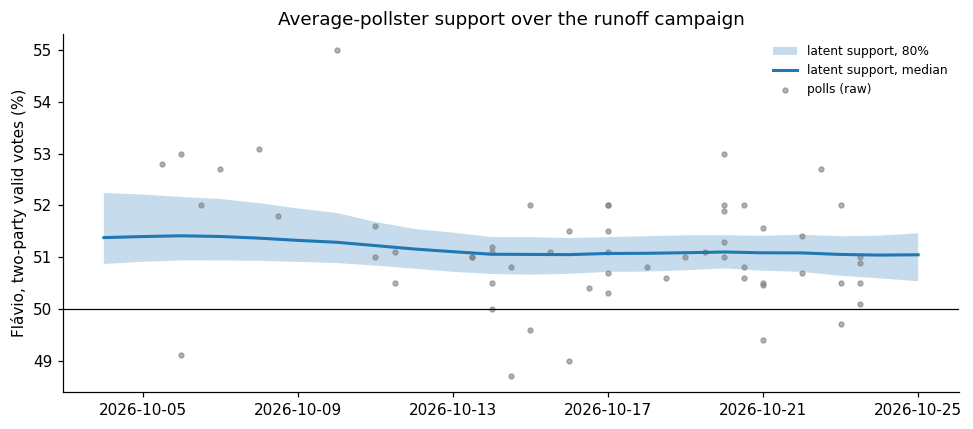

,pollster,house_effect_pp
21,Vox Brasil,-0.25
15,Phoenix,-0.17
14,Palver,-0.09
4,Colectta,-0.09
5,Data Ranking,-0.08
8,Futura,-0.05
3,CNT/MDA,-0.04
2,BTG/Nexus,-0.04
17,Quaest,-0.03
10,Indexa/Broadcast,-0.02


In [9]:
mu = idata.posterior["mu"].values.reshape(-1, F.T_ELECTION + 1)
days = pd.date_range(F.DAY0, F.ELECTION)
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(days, *np.percentile(mu, [10, 90], axis=0), alpha=0.25, label="latent support, 80%")
ax.plot(days, np.median(mu, axis=0), lw=2, label="latent support, median")
ax.scatter(df["mid"], df["y"], s=10, c="grey", alpha=0.6, label="polls (raw)")
ax.axhline(50, color="k", lw=0.8); ax.set_ylabel("Flávio, two-party valid votes (%)")
ax.set_title("Average-pollster support over the runoff campaign"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "latent.png"); plt.show()

house = pd.DataFrame({"pollster": fit["houses"],
                      "house_effect_pp": idata.posterior["house"].values.reshape(-1, len(fit["houses"])).mean(0)})
house.sort_values("house_effect_pp").round(2)

## 5. Sensitivity: how much do the assumptions move the answer?

Pre-registered grid on M2:
- Tails of the election-day error, ν ∈ {3, 5, 30}.
- Error spread × {0.75, 1, 1.5}.
- Design effect ∈ {1.5, 2, 3}.
- Low-auditability pollsters dropped.
- Only polls from 2026-10-15 onward.

In [10]:
grid = [A(f"S_nu{nu}", run_class="sensitivity", nu=nu) for nu in (3, 30)] + \
       [A(f"S_errx{s}", run_class="sensitivity", err_scale=s) for s in (0.75, 1.5)] + \
       [A(f"S_deff{d}", run_class="sensitivity", deff=d) for d in (1.5, 3.0)] + \
       [A("S_drop_low_audit", run_class="sensitivity", drop_low_audit=True),
        A("S_window_1015", run_class="sensitivity", window_from="2026-10-15")]
srows = [F.run_arm(cfg)[0] for cfg in grid]
pd.DataFrame(srows)[["arm","p_flavio","median","pi80_low","pi80_high","n_polls","status"]]

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, tau, z, sigma_h, h_raw, sigma_x]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 10 seconds.


There were 3 divergences after tuning. Increase `target_accept` or reparameterize.


...

NUTS: [mu0, tau, z, sigma_h, h_raw, sigma_x]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 6 seconds.


There were 3 divergences after tuning. Increase `target_accept` or reparameterize.


Sampling: [y]


,arm,p_flavio,median,pi80_low,pi80_high,n_polls,status
0,S_nu3,0.8309,51.601,49.333,53.995,58,ok
1,S_nu30,0.8628,51.604,49.735,53.483,58,ok
2,S_errx0.75,0.9051,51.618,50.029,53.201,58,ok
3,S_errx1.5,0.7625,51.574,48.491,54.514,58,ok
4,S_deff1.5,0.8452,51.600,49.511,53.639,58,ok
5,S_deff3.0,0.8494,51.633,49.556,53.713,58,ok
6,S_drop_low_audit,0.8330,51.566,49.493,53.633,55,ok
7,S_window_1015,0.8438,51.563,49.486,53.697,38,ok


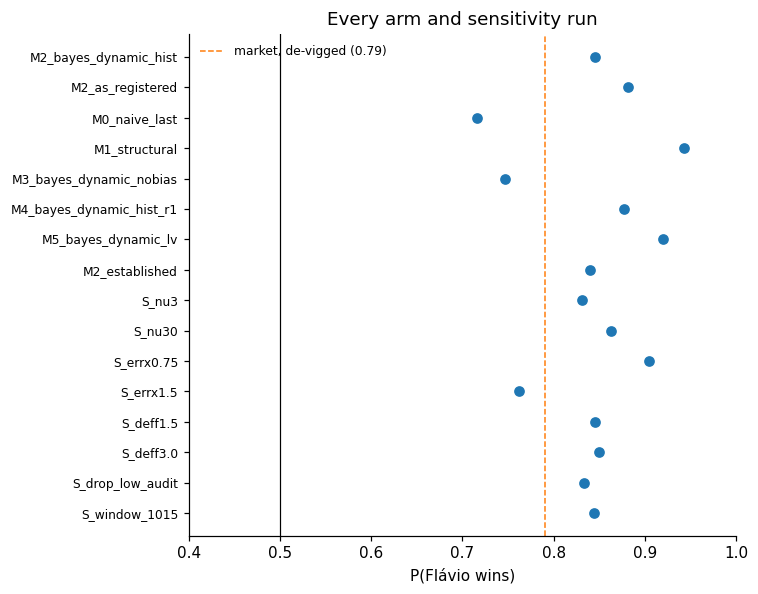

In [11]:
allrows = pd.DataFrame(rows + srows)
mkt = F.market_comparator()
fig, ax = plt.subplots(figsize=(7, 5.5))
yy = np.arange(len(allrows))[::-1]
ax.scatter(allrows["p_flavio"], yy, zorder=3)
ax.axvline(0.5, color="k", lw=0.8); ax.axvline(mkt, color="tab:orange", ls="--", lw=1, label=f"market, de-vigged ({mkt:.2f})")
ax.set_yticks(yy, allrows["arm"], fontsize=8); ax.set_xlabel("P(Flávio wins)"); ax.set_xlim(0.4, 1)
ax.set_title("Every arm and sensitivity run"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "arms.png"); plt.show()

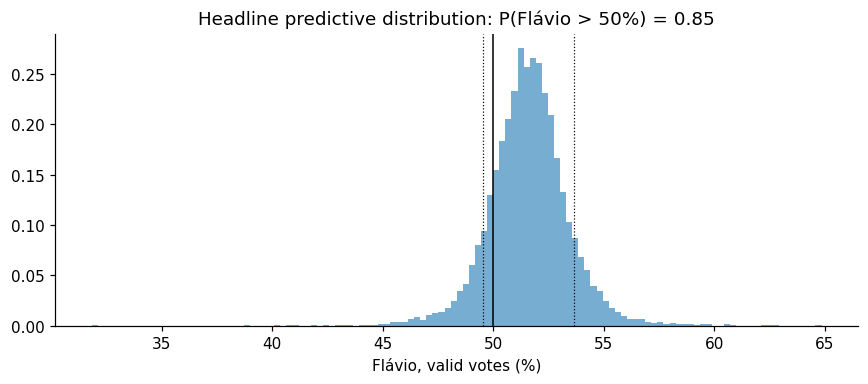

In [12]:
v = draws["M2_bayes_dynamic_hist"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(v, bins=120, density=True, alpha=0.6)
for q in np.percentile(v, [10, 90]): ax.axvline(q, ls=":", c="k", lw=0.8)
ax.axvline(50, c="k", lw=1); ax.set_xlabel("Flávio, valid votes (%)")
ax.set_title(f"Headline predictive distribution: P(Flávio > 50%) = {(v > 50).mean():.2f}")
fig.tight_layout(); fig.savefig(FIG / "predictive.png"); plt.show()

## 6. The frozen forecast

The cell below writes `prereg/forecast_frozen.json`, the object that gets hashed and timestamped before the polls close. Part C scores it, and nothing after this cell can change it.

In [13]:
head = rows[0]
frozen = {
    "question": "P(Flavio Bolsonaro valid-vote share > 50%) in the 2026-10-25 runoff",
    "headline_arm": head["arm"], "p_flavio": head["p_flavio"], "p_lula": round(1 - head["p_flavio"], 4),
    "median_flavio_vv": head["median"], "pi80": [head["pi80_low"], head["pi80_high"]],
    "pi95": [head["pi95_low"], head["pi95_high"]],
    "arms": {r["arm"]: {k: r[k] for k in ("p_flavio", "median", "pi80_low", "pi80_high")} for r in rows},
    "market_comparator_p_flavio": round(mkt, 4), "herding": herd, "environment": env,
    "disclaimer": "Measurement exercise. Not an endorsement of any candidate.",
}
out = ROOT / "prereg" / "forecast_frozen.json"
assert not out.exists(), "forecast already frozen; never overwrite"
out.write_text(json.dumps(frozen, indent=2, default=float))
print(json.dumps({k: frozen[k] for k in ("p_flavio","p_lula","median_flavio_vv","pi80","pi95","market_comparator_p_flavio")}, indent=2))

{
  "p_flavio": 0.8456,
  "p_lula": 0.1544,
  "median_flavio_vv": 51.588,
  "pi80": [
    49.53,
    53.658
  ],
  "pi95": [
    47.973,
    55.154
  ],
  "market_comparator_p_flavio": 0.791
}
